# From a COLMAP capture to a trained splat model

This notebook goes through the real 3DGS pipeline on the Mip-NeRF 360 **bonsai** scene
(292 photos taken around a bonsai on a table, posed by COLMAP):

1. Load the COLMAP model with the official `pycolmap` (poses, intrinsics, sparse points) and
   rescale the intrinsics to the 780x520 training images.
2. Visualise the capture: camera frustums, sparse points, the 1-in-8 train/test split.
3. Compare three ways to **initialise** the Gaussians: SfM sparse points, uniform random
   points, and a **feed-forward** point map from Depth Anything 3 (DA3), which saw the
   images without poses and was Sim(3)-aligned to the COLMAP cameras.
4. Run the training loop (L1 + D-SSIM loss, SH schedule, adaptive density control) live
   for a few thousand steps and look at the curves and a held-out view.

The full 7k-step runs for the three initialisations come from `scripts/train.py` and are
analysed in notebook 03.

**What you'll learn**: COLMAP conventions (`cam_from_world`, PINHOLE intrinsics), scene
scale, why initialisation matters, how densification and pruning change the number of
Gaussians, and the standard novel-view evaluation protocol.

**Prerequisites**: notebook 01; `make data-11_gaussian_splatting`; the DA3 initialisation
`python projects/11_gaussian_splatting/scripts/make_da3_init.py` (about 10 s on the GPU).
Runtime: about 2 minutes on an RTX 5060 Laptop GPU (8 GB).

## Setup

In [1]:
# --- Setup: imports, device, repo-relative paths, plot style ---
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from cvlab import viz
from cvlab.device import setup
from cvlab.io import data_dir, load_json, project_dir, repo_root

PROJECT = "11_gaussian_splatting"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import splatkit as S  # noqa: E402

device = setup(seed=0)
viz.set_style()
SCENE_DIR = data_dir("mipnerf360", "bonsai")
RESULTS = project_dir(PROJECT) / "results"
print("scene:", SCENE_DIR.relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
scene: data/mipnerf360/bonsai


## 1. The COLMAP model

COLMAP stores three files in `sparse/0/`: `cameras.bin` (intrinsics), `images.bin` (one pose
per photo plus its 2D keypoints) and `points3D.bin` (triangulated points with colour, track
and reprojection error). A pose is `cam_from_world`, $T_{cw}=[R\,|\,\mathbf t]$, which maps world
points into the OpenCV camera frame (x right, y down, z forward):
$\mathbf X_c = R\,\mathbf X_w + \mathbf t$. The camera centre is $\mathbf C=-R^\top\mathbf t$.
gsplat calls the same matrix `viewmats`, so no convention change is needed.

The COLMAP camera is 3118x2078 PINHOLE. We train on 780x520 copies, so
$f_x' = f_x\cdot 780/3118$, $c_x' = c_x\cdot 780/3118$ (same for y). Both COLMAP and gsplat
put pixel centres at +0.5, so plain scaling is exact.

In [2]:
# --- Load poses, intrinsics, sparse points and the train/test split ---
# Images are sorted by name; every 8th (index 0, 8, 16, ...) is a held-out test view.
scene = S.load_colmap_scene(SCENE_DIR, images="images_4", test_every=8)
summary = pd.Series({
    "images (train / test)": f"{scene.n_images} ({len(scene.train_idx)} / {len(scene.test_idx)})",
    "COLMAP camera": f"{scene.camera_model} {scene.colmap_size[0]}x{scene.colmap_size[1]}",
    "training resolution": f"{scene.widths[0]}x{scene.heights[0]}",
    "fx, fy, cx, cy at 780x520 [px]": ", ".join(f"{v:.1f}" for v in scene.K[0][[0, 1, 0, 1],
                                                                       [0, 1, 2, 2]]),
    "sparse points": f"{len(scene.points):,}",
    "mean track length [images]": f"{scene.points_track_len.mean():.2f}",
    "median reprojection error [px]": f"{np.median(scene.points_error):.3f}",
    "scene scale (1.1 x max camera dist.) [COLMAP units]": f"{scene.scene_scale:.3f}",
}, name="bonsai")
summary.to_frame()

,bonsai
images (train / test),292 (255 / 37)
COLMAP camera,PINHOLE 3118x2078
training resolution,780x520
"fx, fy, cx, cy at 780x520 [px]","806.2, 806.5, 390.0, 260.0"
sparse points,"206,613"
mean track length [images],8.69
median reprojection error [px],0.659
scene scale (1.1 x max camera dist.) [COLMAP units],5.166


## 2. Looking at the capture

The photographer walked a loop around the table. The plot shows the sparse SfM points
(subsampled, true colours) with the training cameras in blue and the held-out test cameras
in orange. The **look-at centre** is the point closest to all optical axes, found by least
squares: minimise $\sum_i\lVert(I-\mathbf d_i\mathbf d_i^\top)(\mathbf p-\mathbf o_i)\rVert^2$,
which gives the linear system $\big(\sum_i (I-\mathbf d_i\mathbf d_i^\top)\big)\mathbf p =
\sum_i (I-\mathbf d_i\mathbf d_i^\top)\mathbf o_i$. The novel-view orbit in notebook 03 is
built around this point.

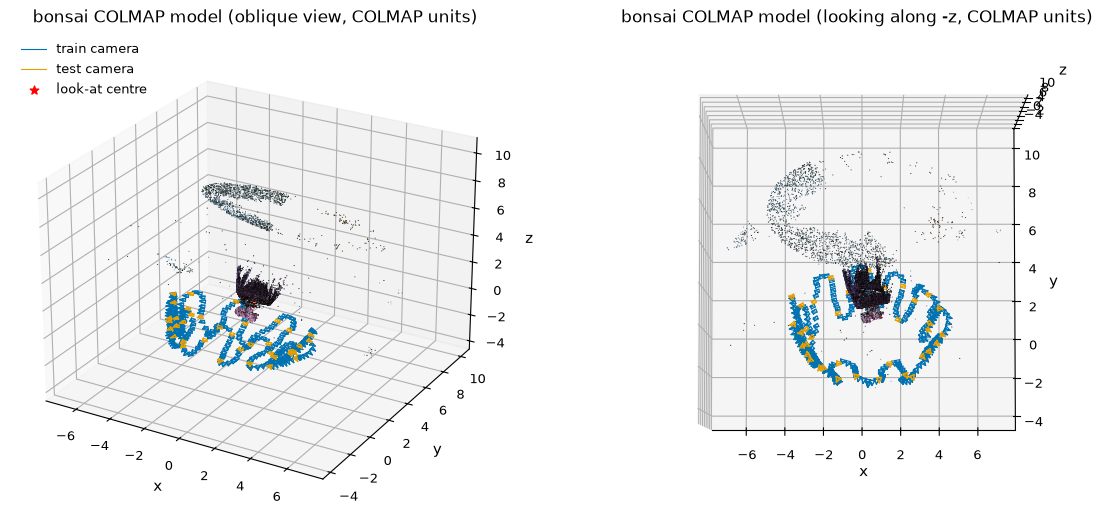

estimated up = [ 0.075 -0.765 -0.639] | look-at centre = [0.403 1.519 1.677]


In [3]:
# --- 3D view of cameras + sparse points (two viewpoints) ---
# COLMAP's world frame is arbitrary; we estimate "up" from the cameras (OpenCV y = down).
c2w = scene.c2w
target = S.closest_point_to_rays(scene.centers, c2w[:, :3, 2])
up = S.fit_up_vector(c2w)
near = np.linalg.norm(scene.points - target, axis=1) < 1.5 * scene.scene_scale  # crop far outliers
pts, cols = scene.points[near], scene.points_rgb[near] / 255.0
fig = plt.figure(figsize=(12, 5.2))
for k, (elev, azim, title) in enumerate([(25, -60, "oblique view"), (85, -90, "looking along -z")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    viz.plot_point_cloud(pts, cols, ax=ax, max_points=25_000, size=0.6, elev=elev, azim=azim)
    viz.plot_camera_frustums(ax, c2w[scene.train_idx], scene.K[0], scene.widths[0],
                             scene.heights[0], scale=0.25, color_rgb=viz.color(0, unit=True),
                             label="train camera")
    viz.plot_camera_frustums(ax, c2w[scene.test_idx], scene.K[0], scene.widths[0],
                             scene.heights[0], scale=0.25, color_rgb=viz.color(1, unit=True),
                             label="test camera")
    ax.scatter(*target, color="red", s=40, marker="*", label="look-at centre")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    viz.set_axes_equal(ax)
    ax.set_title(f"bonsai COLMAP model ({title}, COLMAP units)")
    if k == 0:
        ax.legend(loc="upper left")
viz.savefig(fig, PROJECT, "scene_cameras")
plt.show()
print(f"estimated up = {up.round(3)} | look-at centre = {target.round(3)}")

Train and test views are interleaved along the same loop, so evaluation measures
**interpolation** between nearby training views. That is the standard protocol for
Mip-NeRF 360 / 3DGS papers, but it is easier than the extrapolation a robot sees when it
drives somewhere new.

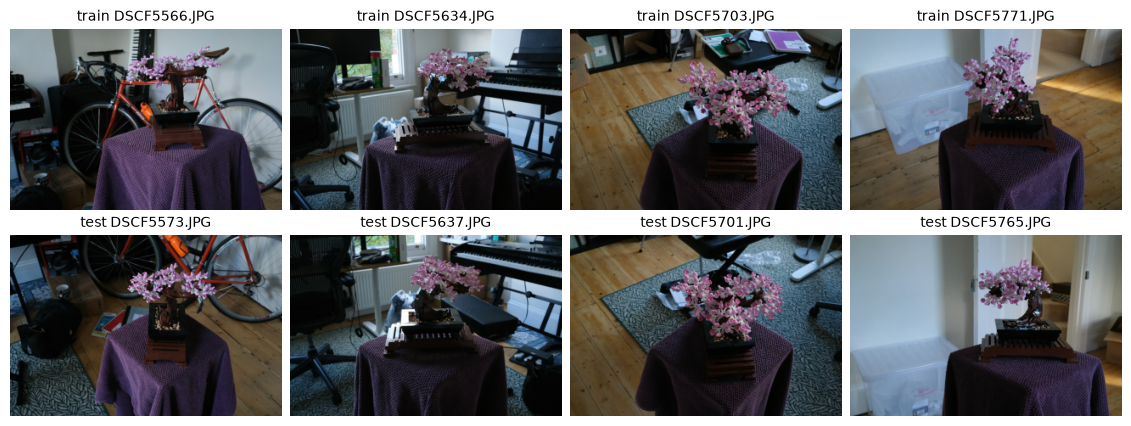

In [4]:
# --- A few training and test images ---
show = list(scene.train_idx[[0, 60, 120, 180]]) + list(scene.test_idx[[1, 9, 17, 25]])
imgs = scene.load_images(show, max_side=320)
titles = [f"train {scene.names[i]}" for i in show[:4]] + [f"test {scene.names[i]}" for i in show[4:]]
fig = viz.show_images(imgs, titles, ncols=4, size=2.8)
plt.show()

## 3. Three initialisations

3DGS needs initial Gaussian centres. Each Gaussian starts isotropic with a radius equal to
the mean distance to its 3 nearest neighbours, opacity 0.1 and the colour of its point.

| init | where the points come from | needs |
|---|---|---|
| **COLMAP** | the 206k triangulated SfM points | a full SfM run (features, matching, bundle adjustment) |
| **random** | 100k points uniform in a cube of half-size 3 x scene scale, random colours | nothing |
| **DA3 feed-forward** | depth maps + poses predicted by Depth Anything 3 from 32 *unposed* training images in one forward pass, back-projected and Sim(3)-aligned to the COLMAP cameras | the DA3-BASE network (135 M parameters), seconds of GPU time |

For DA3, the predicted camera centres $\mathbf c_i^{\text{DA3}}$ are aligned to the COLMAP
centres with Umeyama's closed form,
$\min_{s,R,\mathbf t}\sum_i\lVert \mathbf c_i^{\text{COLMAP}}-(sR\,\mathbf c_i^{\text{DA3}}+\mathbf t)\rVert^2$,
and every DA3 point is mapped with the same $(s,R,\mathbf t)$. The fit residuals measure the
quality of the feed-forward poses. The point map is subsampled to the same number of points
as the SfM model (206k), so the comparison is about geometry, not point count.

In [5]:
# --- DA3 feed-forward initialisation: alignment quality (from make_da3_init.py) ---
# The script ran DA3-BASE once on 32 evenly spaced training views; we load its outputs.
da3 = load_json(RESULTS / "da3_init.json")
da3_npz = np.load(repo_root() / da3["npz"])
pd.Series({
    "model": da3["model"],
    "views (unposed input)": da3["n_views"],
    "network input [px]": "x".join(map(str, da3["processed_hw"][::-1])),
    "inference time [s]": round(da3["inference_s"], 2),
    "peak VRAM [MiB]": round(da3["peak_vram_mb"]),
    "Sim(3) scale (COLMAP / DA3)": round(da3["sim3_scale"], 4),
    "camera-centre RMSE [% of scene scale]": round(100 * da3["center_rmse_rel"], 2),
    "median rotation error [deg]": round(da3["rot_err_median_deg"], 2),
    "max rotation error [deg]": round(da3["rot_err_max_deg"], 2),
    "median dist. COLMAP pt -> DA3 [% scene scale]": round(100 * da3["colmap_to_da3_median_rel"], 2),
    "median dist. DA3 pt -> COLMAP [% scene scale]": round(100 * da3["da3_to_colmap_median_rel"], 2),
    "points kept / back-projected": f"{da3['n_points_kept']:,} / {da3['n_points_raw']:,}",
}, name="DA3 init").to_frame()

,DA3 init
model,depth-anything/DA3-BASE
views (unposed input),32
network input [px],504x336
inference time [s],2.13
peak VRAM [MiB],3079
Sim(3) scale (COLMAP / DA3),5.9953
camera-centre RMSE [% of scene scale],2.56
median rotation error [deg],1.49
max rotation error [deg],3.97
median dist. COLMAP pt -> DA3 [% scene scale],0.53


The camera-centre residuals are a few percent of the scene scale and the rotations agree
to about a degree, so the feed-forward poses are close to the SfM ones. Below are DA3's
depth and confidence maps for four of the 32 input views. Only pixels at or above the 40th
confidence percentile are back-projected. The dropped pixels (black in the bottom row) are
mostly the far background, so the DA3 point map covers the bonsai and the table densely but
the room behind them only sparsely.

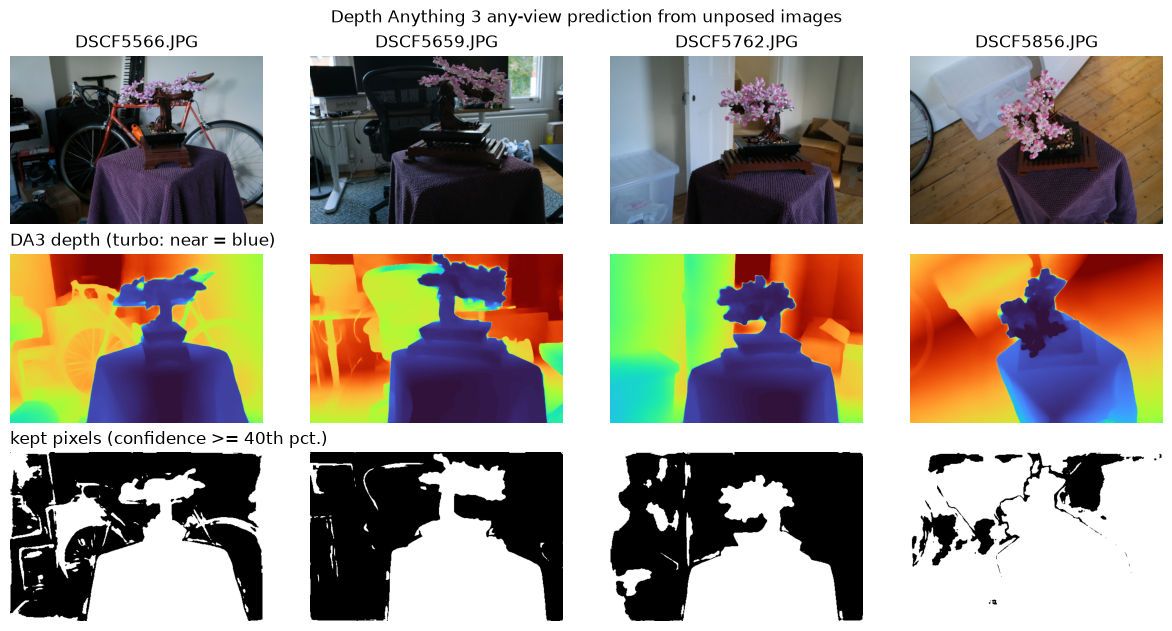

In [6]:
# --- DA3 depth and confidence for four of the 32 input views ---
# Depth is in DA3's own arbitrary scale (Sim(3) alignment fixes it later); low-confidence
# pixels (below the 40th percentile) are dropped before back-projection.
fig, axes = plt.subplots(3, 4, figsize=(12, 6.2))
for k in range(4):
    axes[0, k].imshow(da3_npz["show_rgb"][k])
    axes[0, k].set_title(scene.names[int(da3_npz["show_views"][k])])
    axes[1, k].imshow(viz.colorize_depth(da3_npz["show_depth"][k].astype(np.float32)))
    conf = da3_npz["show_conf"][k].astype(np.float32)
    im = axes[2, k].imshow(conf >= float(da3_npz["conf_threshold"]), cmap="gray")
for ax in axes.flat:
    ax.axis("off")
axes[1, 0].set_title("DA3 depth (turbo: near = blue)", loc="left")
axes[2, 0].set_title("kept pixels (confidence >= 40th pct.)", loc="left")
fig.suptitle("Depth Anything 3 any-view prediction from unposed images")
plt.show()

**What the training starts from.** gsplat can render any set of Gaussians, including the
untrained initial ones. Rendering the three initialisations from the same held-out camera
(step 0, before any optimisation) shows the starting point of each run: SfM points are
sparse but accurate, DA3 points are dense, and random points are noise.

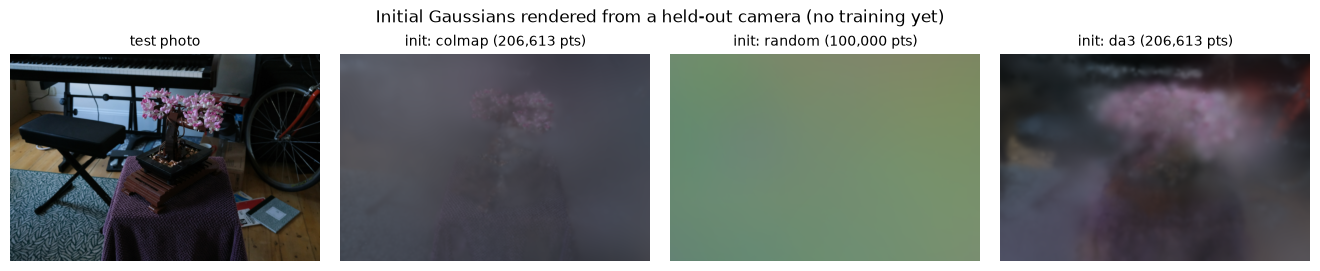

In [7]:
# --- Render the three initial Gaussian sets from a test camera (step 0) ---
inits = {k: S.init_points(scene, k, da3_path=repo_root() / da3["npz"]) for k in
         ("colmap", "random", "da3")}
cfg0 = S.TrainConfig(sh_degree=0)
i_test = int(scene.test_idx[5])
vm = torch.as_tensor(scene.w2c[i_test:i_test + 1], dtype=torch.float32, device=device)
Kt = torch.as_tensor(scene.K[i_test:i_test + 1], dtype=torch.float32, device=device)
init_renders = {}
for name, (p, c) in inits.items():
    sp, _ = S.create_splats(p, c, scene.scene_scale, cfg0, device=device)
    with torch.no_grad():
        out, _, _ = S.render(sp, vm, Kt, scene.widths[i_test], scene.heights[i_test], 0)
    init_renders[name] = out[0].clamp(0, 1).cpu().numpy()
    del sp
gt_test = scene.load_images([i_test])[0]
fig = viz.show_images([gt_test] + list(init_renders.values()),
                      ["test photo"] + [f"init: {k} ({len(inits[k][0]):,} pts)"
                                        for k in init_renders], ncols=4, size=3.3)
fig.suptitle("Initial Gaussians rendered from a held-out camera (no training yet)")
viz.savefig(fig, PROJECT, "init_renders")
plt.show()

## 4. The training loop, live

`splatkit.train` follows gsplat's reference trainer. One step:

1. pick a random training image (one view per step, no repeats within an epoch);
2. render it with SH degree $\min(\lfloor\text{step}/1000\rfloor, 3)$;
3. loss $\mathcal L = 0.8\,\lVert\hat I-I\rVert_1 + 0.2\,(1-\mathrm{SSIM}(\hat I, I))$;
4. Adam step on every parameter group (the position learning rate decays exponentially from
   $1.6\cdot10^{-4}\times$ scene scale to 1% of that);
5. **adaptive density control** (gsplat `DefaultStrategy`), every 100 steps from step 500:
   Gaussians whose accumulated view-space positional gradient exceeds $2\cdot10^{-4}$ are
   **cloned** if they are small (under-reconstruction) or **split** in two if they are large
   (over-reconstruction). Gaussians with opacity < 0.005 or that are too large are **pruned**.
   Every 3000 steps all opacities are **reset** to at most 0.01, so that floaters must "earn"
   their opacity back or get pruned.

The cell below trains from the COLMAP initialisation for 3,500 steps (including one
opacity reset at step 3000) and evaluates the 37 test views every 500 steps.

In [8]:
# --- Live training run (COLMAP init, 3500 steps) ---
# Images are kept as pinned uint8 tensors on the CPU and copied to the GPU per step.
images = S.images_to_tensors(scene.load_images())
cfg = S.TrainConfig(steps=3500, eval_every=500, log_every=25)
pts0, rgb0 = inits["colmap"]
splats, res = S.train(scene, images, pts0, rgb0, cfg, device=device, eval_images=images)
final = S.evaluate(splats, scene, images, scene.test_idx, sh_degree=3, device=device, lpips=True)
print(f"train time {res.train_time_s:.1f} s | peak VRAM {res.peak_vram_mb:.0f} MiB | "
      f"{splats['means'].shape[0]:,} Gaussians | test PSNR {final['psnr']:.2f} dB, "
      f"SSIM {final['ssim']:.4f}, LPIPS {final['lpips']:.4f}")

step    500 | loss 0.0876 | test PSNR 23.69 dB |   206613 Gaussians | 8 s


step   1000 | loss 0.0366 | test PSNR 26.00 dB |   314153 Gaussians | 16 s


step   1500 | loss 0.0401 | test PSNR 27.45 dB |   488815 Gaussians | 27 s


step   2000 | loss 0.0361 | test PSNR 28.04 dB |   627512 Gaussians | 39 s


step   2500 | loss 0.0269 | test PSNR 28.71 dB |   732233 Gaussians | 53 s


step   3000 | loss 0.0638 | test PSNR 29.09 dB |   809066 Gaussians | 68 s


step   3500 | loss 0.0354 | test PSNR 29.18 dB |   879174 Gaussians | 85 s


train time 84.6 s | peak VRAM 1362 MiB | 879,174 Gaussians | test PSNR 29.18 dB, SSIM 0.9272, LPIPS 0.0960


## 5. A held-out view

The render is compared with the photo of a test camera that was never used for training.
The absolute-error map shows where the model is still wrong; look for thin structures
(bicycle spokes, leaf edges) and high-contrast edges.

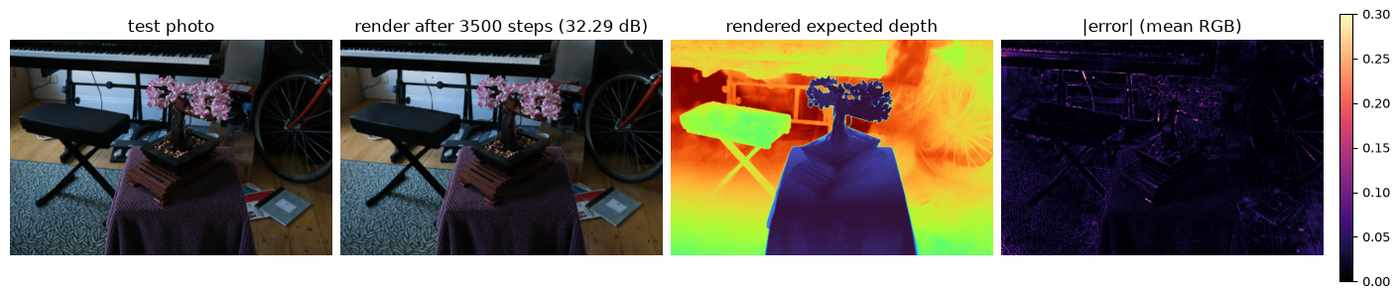

In [9]:
# --- Render a test view: RGB, expected depth and error map ---
with torch.no_grad():
    out, alpha, _ = S.render(splats, vm, Kt, scene.widths[i_test], scene.heights[i_test], 3,
                             render_mode="RGB+ED")
pred = out[0, ..., :3].clamp(0, 1).cpu().numpy()
depth = out[0, ..., 3].cpu().numpy()  # expected depth along the optical axis [COLMAP units]
err = np.abs(pred - gt_test / 255.0).mean(-1)
psnr_i = -10 * np.log10(((pred - gt_test / 255.0) ** 2).mean())
fig, axes = plt.subplots(1, 4, figsize=(14, 2.9))
axes[0].imshow(gt_test)
axes[0].set_title("test photo")
axes[1].imshow(pred)
axes[1].set_title(f"render after {cfg.steps} steps ({psnr_i:.2f} dB)")
axes[2].imshow(viz.colorize_depth(depth))
axes[2].set_title("rendered expected depth")
im = axes[3].imshow(err, cmap="magma", vmin=0, vmax=0.3)
axes[3].set_title("|error| (mean RGB)")
fig.colorbar(im, ax=axes[3], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.show()

## Results

Training curves of the live run: the loss and training-view PSNR (logged every 25 steps on
the image of that step), the number of Gaussians (densification adds them, pruning removes
transparent or oversized ones), and the PSNR on the 37 held-out views.

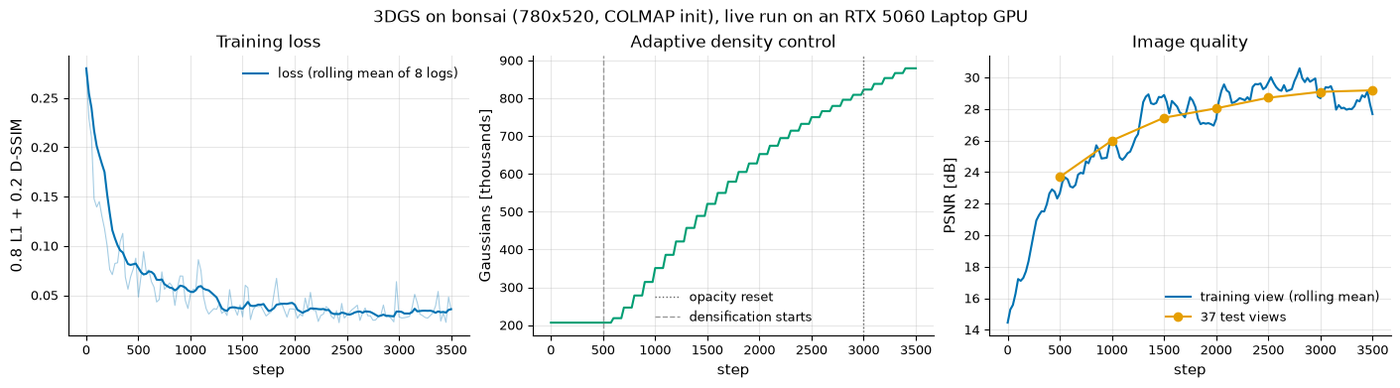

In [10]:
# --- Figure: training curves of the live run (saved for the README) ---
h = pd.DataFrame(res.history)
ev = pd.DataFrame(res.eval_history)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(h["step"], h["loss"], color=viz.color(0, unit=True), alpha=0.35, lw=0.8)
axes[0].plot(h["step"], h["loss"].rolling(8, min_periods=1).mean(),
             color=viz.color(0, unit=True), label="loss (rolling mean of 8 logs)")
axes[0].set_xlabel("step")
axes[0].set_ylabel("0.8 L1 + 0.2 D-SSIM")
axes[0].set_title("Training loss")
axes[0].legend()
axes[1].plot(h["step"], h["n_gaussians"] / 1e3, color=viz.color(2, unit=True))
for s in range(cfg.reset_every, cfg.steps + 1, cfg.reset_every):
    axes[1].axvline(s, color="0.4", ls=":", lw=1, label="opacity reset" if s == cfg.reset_every
                    else None)
axes[1].axvline(cfg.refine_start_iter, color="0.6", ls="--", lw=1, label="densification starts")
axes[1].set_xlabel("step")
axes[1].set_ylabel("Gaussians [thousands]")
axes[1].set_title("Adaptive density control")
axes[1].legend()
axes[2].plot(h["step"], h["train_psnr"].rolling(8, min_periods=1).mean(),
             color=viz.color(0, unit=True), label="training view (rolling mean)")
axes[2].plot(ev["step"], ev["psnr"], "o-", color=viz.color(1, unit=True),
             label="37 test views")
axes[2].set_xlabel("step")
axes[2].set_ylabel("PSNR [dB]")
axes[2].set_title("Image quality")
axes[2].legend()
fig.suptitle("3DGS on bonsai (780x520, COLMAP init), live run on an RTX 5060 Laptop GPU")
viz.savefig(fig, PROJECT, "training_curves")
plt.show()

The summary table lists the measured numbers of the live run: model size before and after
densification, training time (evaluation passes excluded), peak VRAM and the test metrics
on the 37 held-out views.

In [11]:
# --- Summary table of the live run ---
pd.DataFrame([{
    "init": "COLMAP sparse points",
    "steps": cfg.steps,
    "initial Gaussians": res.n_init,
    "final Gaussians": int(splats["means"].shape[0]),
    "train time [s]": round(res.train_time_s, 1),
    "peak VRAM [MiB]": round(res.peak_vram_mb),
    "test PSNR [dB]": round(final["psnr"], 2),
    "test SSIM": round(final["ssim"], 4),
    "test LPIPS (alex)": round(final["lpips"], 4),
}]).set_index("init")

,steps,initial Gaussians,final Gaussians,train time [s],peak VRAM [MiB],test PSNR [dB],test SSIM,test LPIPS (alex)
init,,,,,,,,
COLMAP sparse points,3500,206613,879174,84.6,1362,29.18,0.9272,0.096


**Takeaways**

- `pycolmap` gives everything 3DGS needs: `cam_from_world` is directly gsplat's `viewmats`,
  and intrinsics only need to be rescaled to the training resolution.
- Test PSNR climbs fastest in the first thousand steps; the long tail of training is about
  fine detail. Densification grows the model several-fold (see the table). The opacity
  reset at step 3000 does not visibly shrink it in this run: opacities are clamped to 0.01,
  twice the pruning threshold, and most splats regain opacity before the next pruning pass.
- The 1-in-8 split measures interpolation between training views; real deployments (new
  viewpoints far from the capture) are harder than these numbers suggest.
- Peak VRAM stays well below 8 GB at 780x520. Memory scales with the number of Gaussians
  and the image size, which is the knob to turn on a bigger scene.

## Exercises

Solutions: `projects/11_gaussian_splatting/solutions/ex02_training.py`.

**Exercise 1: filter the SfM points.** Points seen in only two images or with a high
reprojection error are often wrong. Initialise from the points with track length >= 5 and
error < 1 px only, train 1500 steps, and compare test PSNR and the number of Gaussians with an
unfiltered 1500-step run.

In [12]:
# --- Exercise 1: track-length / reprojection-error filter on the initial points ---
# TODO: keep = (scene.points_track_len >= 5) & (scene.points_error < 1.0); train both variants
# with S.TrainConfig(steps=1500, eval_every=0) and compare S.evaluate(...)["psnr"].

**Exercise 2: does view-dependent colour matter here?** Train 2000 steps with
`sh_degree=0` (one colour per Gaussian) and with `sh_degree=3`, then compare test PSNR and
look at the shiny pot and table in a test view.

In [13]:
# --- Exercise 2: SH degree 0 vs 3 ---
# TODO: S.TrainConfig(steps=2000, sh_degree=0, sh_degree_interval=500) vs sh_degree=3;
# evaluate with the matching sh_degree in S.evaluate.